# Практическая работа №2. Основные методы OpenCV. Часть 2

## Задание 1. Загрузка изображения по ссылке

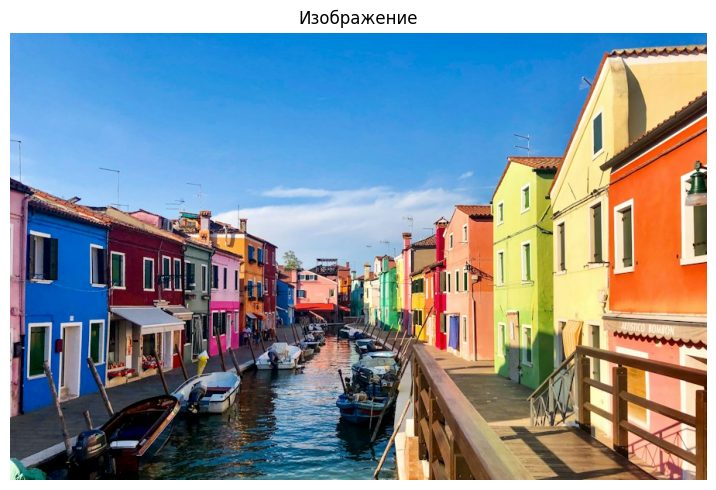

In [1]:
from urllib.request import Request, urlopen
import cv2
import numpy as np
import matplotlib.pyplot as plt


def read_image(url):
    request = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(request, timeout=60) as response:
        buffer = np.frombuffer(response.read(), dtype=np.uint8)
    image = cv2.imdecode(buffer, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('Не удалось открыть изображение')
    return image


def show_images(images, titles, figsize=(10, 4)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize, squeeze=False)
    for ax, image, title in zip(axes[0], images, titles):
        if image.ndim == 2:
            ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()
    plt.close(fig)


url = 'https://images.unsplash.com/photo-1596449971485-15d710844a57?auto=format&fit=max&w=900&q=90'
city = read_image(url)
show_images([city], ['Изображение'], figsize=(8, 5))

## Задание 2. Цветной градиент

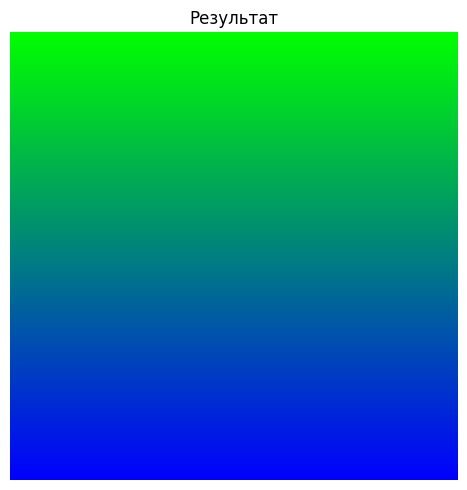

In [2]:
gradient = np.zeros((512, 512, 3), dtype=np.uint8)
values = np.linspace(0, 255, 512).round().astype(np.uint8)
gradient[:, :, 0] = values[:, None]
gradient[:, :, 1] = 255 - values[:, None]
show_images([gradient], ['Результат'], figsize=(5, 5))

## Задание 3. Рисование фигур

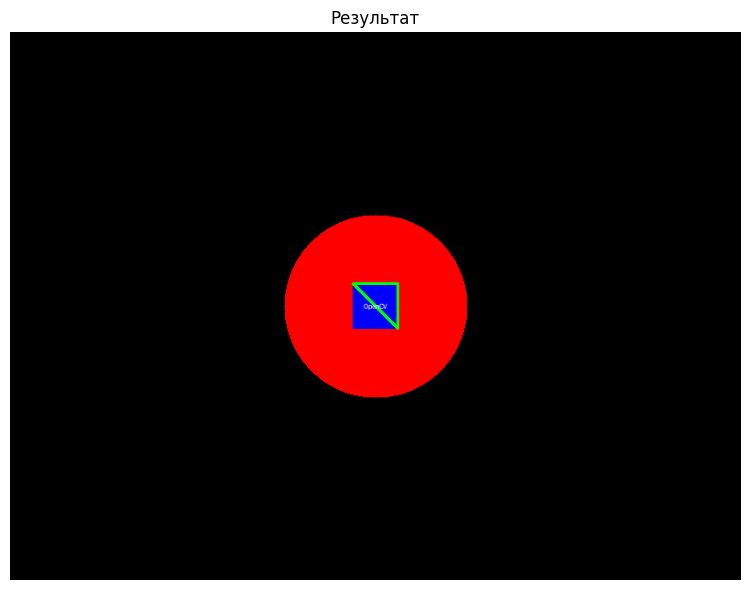

In [3]:
figures = np.zeros((600, 800, 3), dtype=np.uint8)
cv2.circle(figures, (400, 300), 100, (0, 0, 255), -1)
cv2.rectangle(figures, (375, 275), (424, 324), (255, 0, 0), -1)
triangle = np.array([[375, 275], [424, 275], [424, 324]], dtype=np.int32)
cv2.polylines(figures, [triangle], True, (0, 255, 0), 2)
font = cv2.FONT_HERSHEY_COMPLEX
(text_w, text_h), _ = cv2.getTextSize('OpenCV', font, 0.25, 1)
cv2.putText(figures, 'OpenCV', (400 - text_w // 2, 300 + text_h // 2),
            font, 0.25, (255, 255, 255), 1, cv2.LINE_AA)
show_images([figures], ['Результат'], figsize=(8, 6))

## Задание 4. Преобразование области интереса

x1 y1 x2 y2: 160 100 720 500


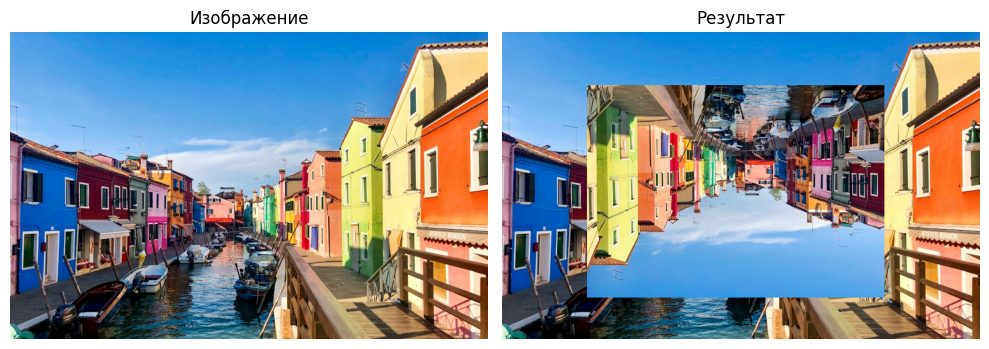

In [4]:
def flip_roi(image):
    x1, y1, x2, y2 = map(int, input('x1 y1 x2 y2: ').split())
    h, w = image.shape[:2]
    if not (0 <= x1 < x2 <= w and 0 <= y1 < y2 <= h):
        raise ValueError('Координаты выходят за границы изображения')
    result = image.copy()
    result[y1:y2, x1:x2] = cv2.flip(image[y1:y2, x1:x2], -1)
    return result


roi_result = flip_roi(city)
show_images([city, roi_result], ['Изображение', 'Результат'])

## Задание 5. Яркость и контраст

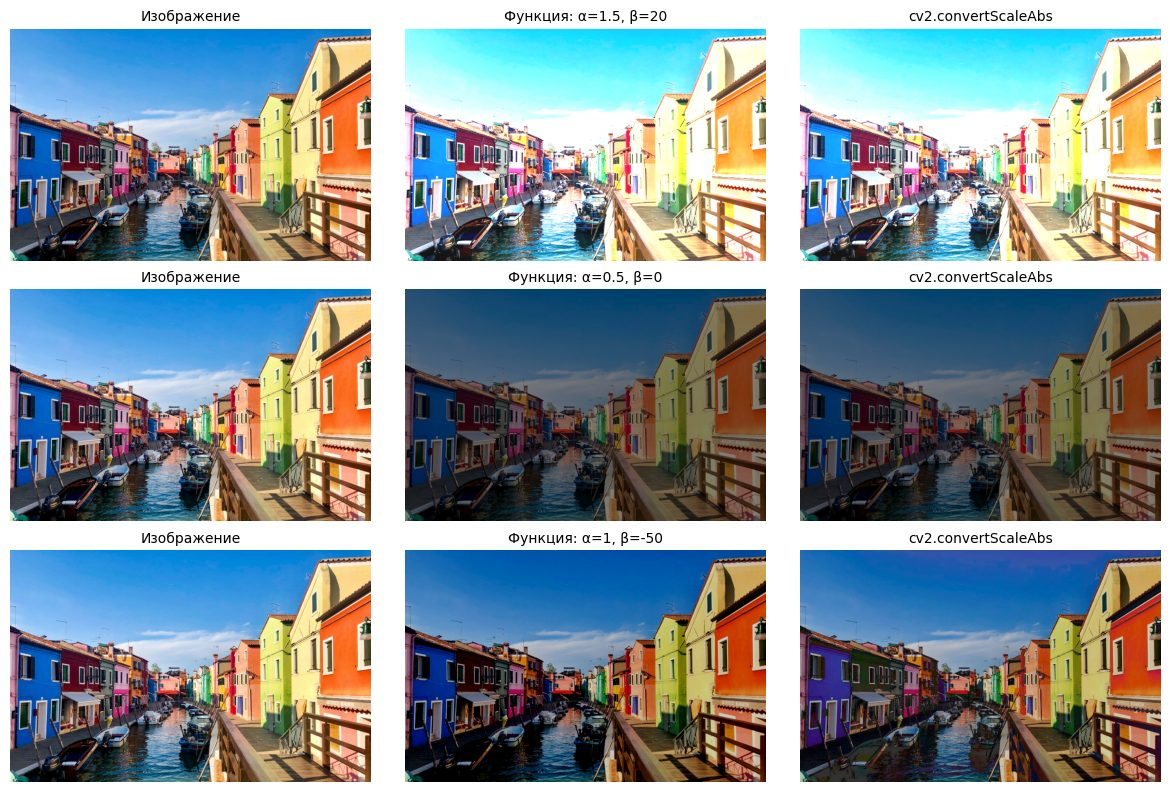

In [5]:
def change_brightness_contrast(image, alpha=1.0, beta=0):
    result = image.astype(np.float32) * alpha + beta
    return np.clip(np.rint(result), 0, 255).astype(np.uint8)


settings = [(1.5, 20), (0.5, 0), (1.0, -50)]
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for row, (alpha, beta) in enumerate(settings):
    own = change_brightness_contrast(city, alpha, beta)
    opencv = cv2.convertScaleAbs(city, alpha=alpha, beta=beta)
    images = [city, own, opencv]
    titles = ['Изображение', f'Функция: α={alpha:g}, β={beta:g}', 'cv2.convertScaleAbs']
    for ax, image, title in zip(axes[row], images, titles):
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=10)
        ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

При неотрицательных значениях αI + β результаты совпадают. Отрицательные значения моя функция обрезает до нуля, а cv2.convertScaleAbs берёт по модулю.

## Комплексное задание 1. Сравнение интерполяции

In [6]:
import pandas as pd
from IPython.display import display


def calculate_mse(original, restored):
    difference = original.astype(np.float32) - restored.astype(np.float32)
    return float(np.mean(difference ** 2))


methods = {'Ближайший сосед': cv2.INTER_NEAREST,
           'Билинейная': cv2.INTER_LINEAR,
           'Бикубическая': cv2.INTER_CUBIC}
rows = []
h, w = city.shape[:2]
for name, method in methods.items():
    for factor in [2, 4]:
        small = cv2.resize(city, (w // factor, h // factor), interpolation=method)
        restored = cv2.resize(small, (w, h), interpolation=method)
        rows.append([name, factor, calculate_mse(city, restored)])
mse_table = pd.DataFrame(rows, columns=['Метод', 'Уменьшение, раз', 'MSE'])
display(mse_table.round({'MSE': 2}))

,Метод,"Уменьшение, раз",MSE
0,Ближайший сосед,2,378.03
1,Ближайший сосед,4,1341.92
2,Билинейная,2,175.05
3,Билинейная,4,434.49
4,Бикубическая,2,138.58
5,Бикубическая,4,505.61


При уменьшении в 2 раза минимальная MSE получилась у бикубической интерполяции, в 4 раза — у билинейной. При более сильном уменьшении ошибка выросла у всех методов. Для этой фотографии подходят эти методы: они дали меньшую ошибку, чем ближайший сосед.

## Комплексное задание 2. HDR-подобный эффект

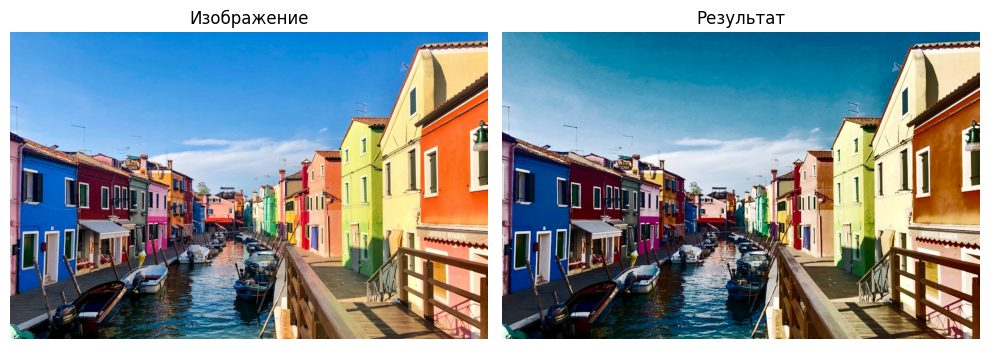

In [7]:
def hdr_effect(image):
    image_float = image.astype(np.float32)
    dark = np.clip(image_float * 0.5, 0, 255)
    normal = image_float
    bright = np.clip(image_float * 1.8, 0, 255)
    merged = np.clip((dark + normal + bright) / 3, 0, 255).astype(np.uint8)
    l, a, b = cv2.split(cv2.cvtColor(merged, cv2.COLOR_BGR2LAB))
    l = cv2.equalizeHist(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


hdr_result = hdr_effect(city)
show_images([city, hdr_result], ['Изображение', 'Результат'])

## Комплексное задание 3. Графические объекты

### 3.1. Создание растра

In [8]:
canvas = np.zeros((1920, 1080, 3), dtype=np.uint8)
rng = np.random.default_rng(23)

### 3.2. Объекты из линий

In [9]:
def add_snowflakes(image, n):
    result = image.copy()
    h, w = result.shape[:2]
    for _ in range(n):
        radius = int(rng.integers(30, 65))
        x = int(rng.integers(radius + 5, w - radius - 5))
        y = int(rng.integers(radius + 5, h // 2 - radius - 5))
        angle = rng.uniform(0, np.pi)
        for step in range(4):
            phi = angle + step * np.pi / 4
            dx, dy = int(radius * np.cos(phi)), int(radius * np.sin(phi))
            cv2.line(result, (x - dx, y - dy), (x + dx, y + dy),
                     (255, 255, 255), 3, cv2.LINE_AA)
    return result

### 3.3. Объекты из кругов

In [10]:
def add_snowmen(image, n):
    result = image.copy()
    h, w = result.shape[:2]
    step = w / max(1, 2 * n)
    for i in range(n):
        radius = int(min(60, step * 0.28))
        x = int((2 * i + 0.5) * step + rng.uniform(-0.1, 0.1) * step)
        y = int(rng.integers(int(h * 0.69), int(h * 0.72)))
        for offset, size in [(0, 1), (-1.6, 0.8), (-2.9, 0.6)]:
            center = (x, int(y + offset * radius))
            cv2.circle(result, center, int(radius * size),
                       (255, 255, 255), -1, cv2.LINE_AA)
    return result

### 3.4. Объекты из полигонов

In [11]:
def add_trees(image, n):
    result = image.copy()
    h, w = result.shape[:2]
    step = w / max(1, 2 * n)
    for i in range(n):
        x = int((2 * i + 1.5) * step + rng.uniform(-0.1, 0.1) * step)
        y = int(rng.integers(h // 2 + 40, h // 2 + 120))
        radius = int(min(65, step * 0.3))
        height = int(rng.integers(200, 270))
        points = np.array([[x, y], [x + radius, y + height // 2],
                           [x + radius // 2, y + height // 2],
                           [x + int(radius * 1.35), y + height],
                           [x - int(radius * 1.35), y + height],
                           [x - radius // 2, y + height // 2],
                           [x - radius, y + height // 2]], dtype=np.int32)
        cv2.fillPoly(result, [points], (65, 160, 40))
        cv2.polylines(result, [points], True, (255, 255, 255), 2)
        trunk = np.array([[x - radius // 5, y + height + 5],
                          [x + radius // 5, y + height + 5],
                          [x + radius // 5, y + height + 45],
                          [x - radius // 5, y + height + 45]], dtype=np.int32)
        cv2.fillPoly(result, [trunk], (65, 160, 40))
        cv2.polylines(result, [trunk], True, (255, 255, 255), 2)
    return result

### 3.5. Наложение текста

In [12]:
def add_text(image, text):
    result = image.copy()
    h, w = result.shape[:2]
    font = cv2.FONT_HERSHEY_COMPLEX
    (text_w, text_h), _ = cv2.getTextSize(text, font, 2, 3)
    point = ((w - text_w) // 2, 7 * h // 8 + text_h // 2)
    cv2.putText(result, text, point, font, 2, (255, 255, 255), 3, cv2.LINE_AA)
    return result

### 3.6. Применение функций

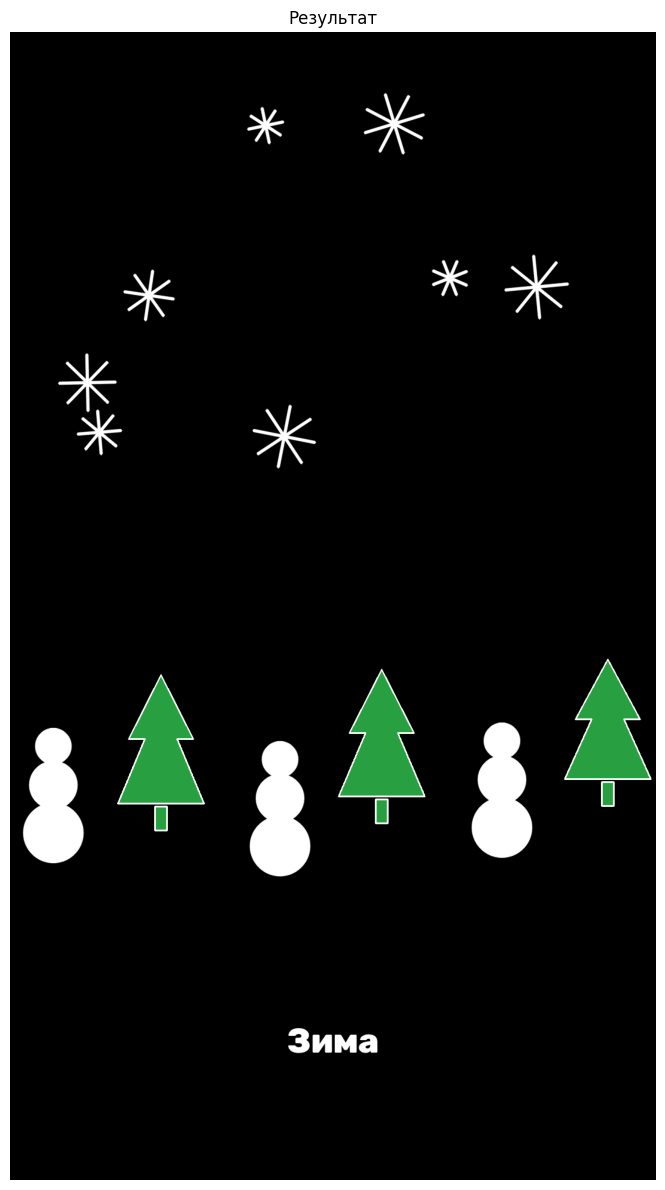

In [13]:
winter = add_snowflakes(canvas, 8)
winter = add_snowmen(winter, 3)
winter = add_trees(winter, 3)
winter = add_text(winter, 'Зима')
show_images([winter], ['Результат'], figsize=(7, 12))

## Комплексное задание 4. Обработка SAR-изображения

### 4.1. Загрузка изображения

In [14]:
from pathlib import Path
from shutil import copyfileobj
import tempfile
import re
import tifffile as tiff


workdir = tempfile.TemporaryDirectory()
files = Path(workdir.name)
public_url = 'https://cloud.mail.ru/public/HEvc/aY7eMhHor'
request = Request(public_url, headers={'User-Agent': 'Mozilla/5.0'})
with urlopen(request, timeout=60) as response:
    page = response.read().decode('utf-8')
server = re.search(r'"weblink_get":\{"count":"\d+","url":"([^"]+)"', page).group(1)
sar_path = files / 'sar.tif'
download = Request(server + '/HEvc/aY7eMhHor', headers={'User-Agent': 'Mozilla/5.0'})
with urlopen(download, timeout=120) as response, sar_path.open('wb') as output:
    copyfileobj(response, output)
sar = tiff.imread(sar_path)

### 4.2. Анализ изображения

In [15]:
print(type(sar))
print(sar.dtype)
print(sar.shape)

<class 'numpy.ndarray'>
uint16
(1422, 14958, 4)


Канал 1


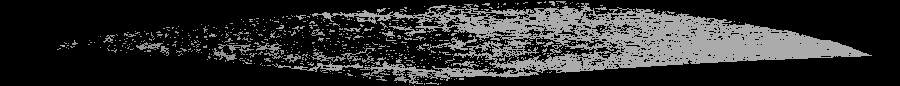

Канал 2


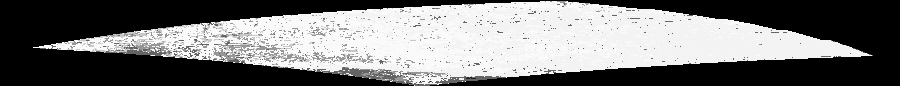

Канал 3


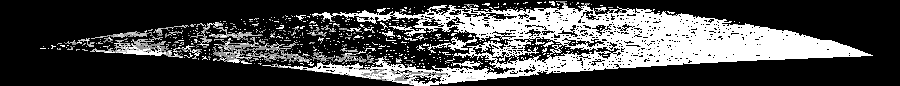

Канал 4


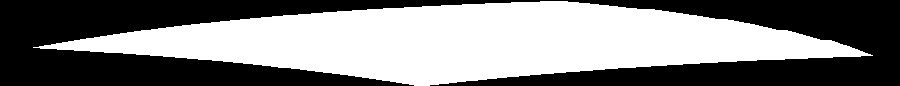

In [16]:
try:
    from google.colab.patches import cv2_imshow
except ImportError:
    from PIL import Image

    def cv2_imshow(image):
        display(Image.fromarray(np.clip(image, 0, 255).astype(np.uint8)))


for i in range(sar.shape[2]):
    print(f'Канал {i + 1}')
    preview = cv2.resize(sar[:, :, i], (900, 86), interpolation=cv2.INTER_NEAREST)
    cv2_imshow(preview)

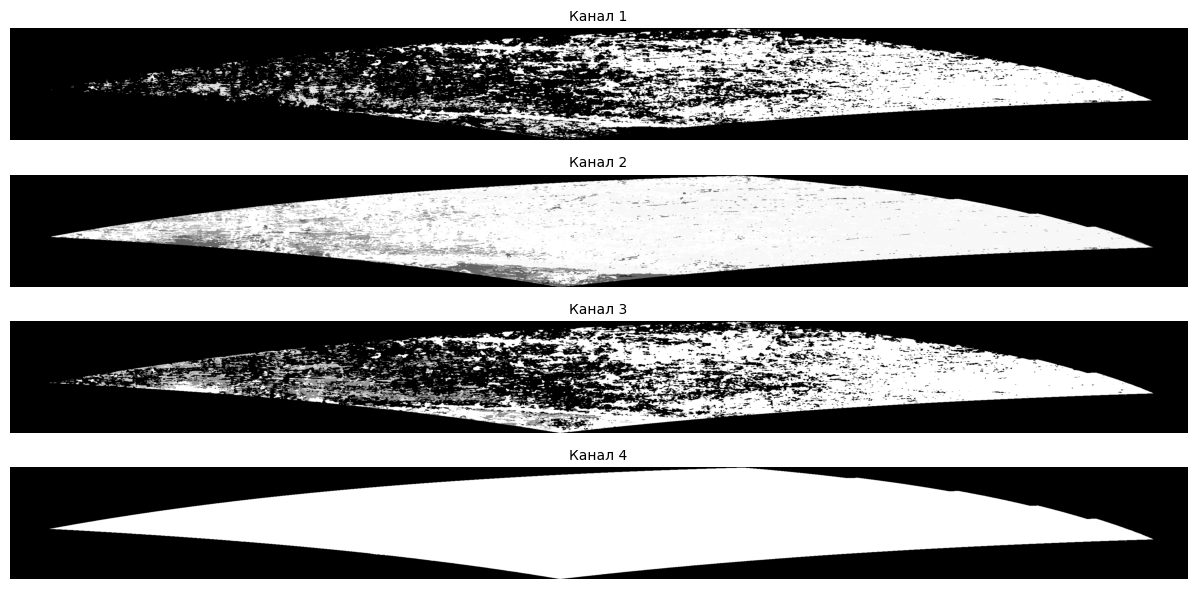

In [17]:
fig, axes = plt.subplots(sar.shape[2], 1, figsize=(14, 6))
for i, ax in enumerate(axes):
    ax.imshow(sar[:, :, i], cmap='gray')
    ax.set_title(f'Канал {i + 1}', fontsize=10)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

Изображение имеет тип uint16 и четыре канала, фактические значения находятся в диапазоне 0–255. Четвёртый канал содержит только 0 и 255. Matplotlib автоматически растягивает яркость каждого канала, поэтому первый канал выглядит светлее, чем при cv2_imshow.

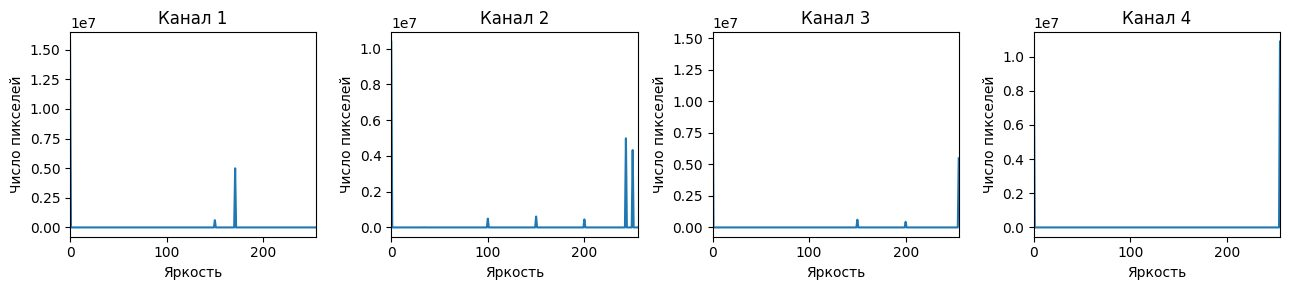

In [18]:
def img2hist(image):
    channels = cv2.split(image)
    fig, axes = plt.subplots(1, len(channels), figsize=(13, 3), squeeze=False)
    for i, (ax, channel) in enumerate(zip(axes[0], channels)):
        hist = cv2.calcHist([channel.astype(np.float32)], [0], None, [256], [0, 256])
        ax.plot(hist.ravel())
        ax.set(title=f'Канал {i + 1}', xlim=(0, 255),
               xlabel='Яркость', ylabel='Число пикселей')
    fig.tight_layout()
    plt.show()
    plt.close(fig)


img2hist(sar)

### 4.3. Нормализация

In [19]:
def img2dB(image_o, eps=1e-10):
    image = image_o.copy()
    dB = np.where(image > eps, image, -10)
    np.log10(dB, out=dB, where=dB > 0, casting='unsafe')
    return dB


sar_db = img2dB(sar.astype(np.float32))

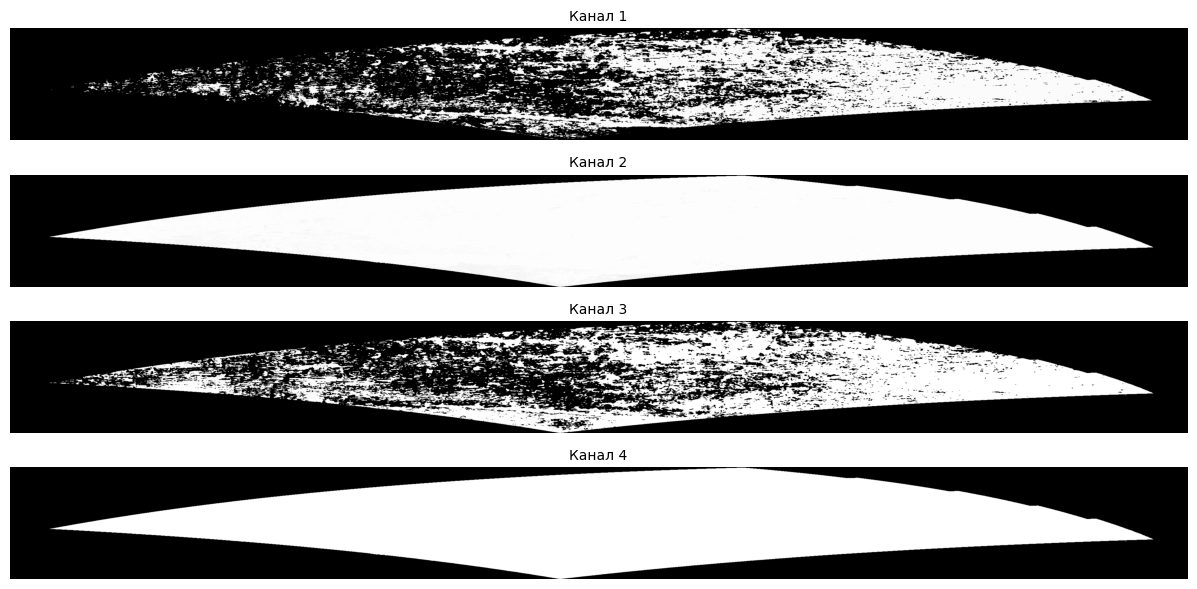

In [20]:
def img_to_uint(I):
    I = I.astype(np.float32)
    mn, mx = I.min(), I.max()
    if mx == mn:
        return np.zeros_like(I, dtype=np.uint8)
    return ((I - mn) / (mx - mn) * 255).astype(np.uint8)


sar_uint = img_to_uint(sar_db)
fig, axes = plt.subplots(sar_uint.shape[2], 1, figsize=(14, 6))
for i, ax in enumerate(axes):
    ax.imshow(sar_uint[:, :, i], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Канал {i + 1}', fontsize=10)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

### 4.4. Повышение контрастности и объединение каналов

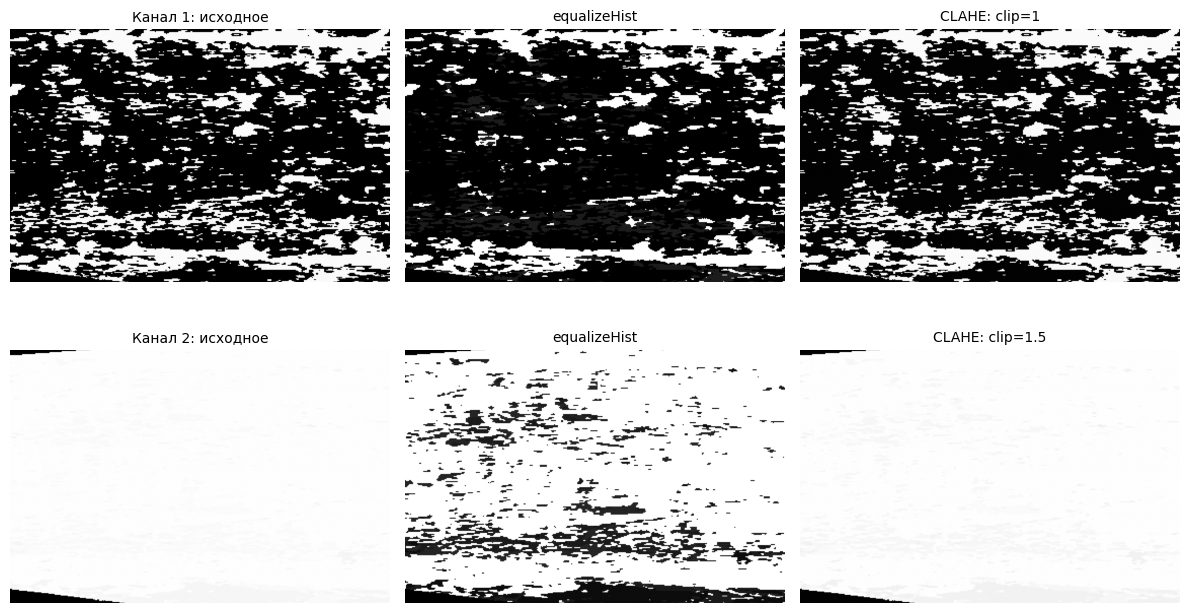

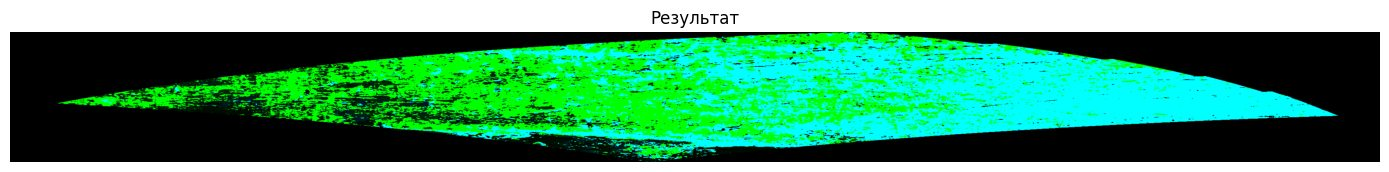

In [21]:
channel_1 = sar_uint[:, :, 0]
channel_2 = sar_uint[:, :, 1]
equalized_1 = cv2.equalizeHist(channel_1)
equalized_2 = cv2.equalizeHist(channel_2)
clahe_1 = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(8, 8)).apply(channel_1)
clahe_2 = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8)).apply(channel_2)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, images in enumerate([[channel_1, equalized_1, clahe_1],
                              [channel_2, equalized_2, clahe_2]]):
    titles = [f'Канал {row + 1}: исходное', 'equalizeHist',
              f'CLAHE: clip={1.0 if row == 0 else 1.5:g}']
    for ax, image, title in zip(axes[row], images, titles):
        ax.imshow(image[200:1200, 5000:6500], cmap='gray', vmin=0, vmax=255)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

corrected_1 = equalized_1
corrected_2 = equalized_2
ratio = np.floor_divide(corrected_1, corrected_2,
                        out=np.zeros_like(corrected_1), where=corrected_2 != 0)
composite = np.dstack((corrected_1, corrected_2, ratio))
show_images([composite], ['Результат'], figsize=(14, 3))

### 4.5. Сегментация каналов

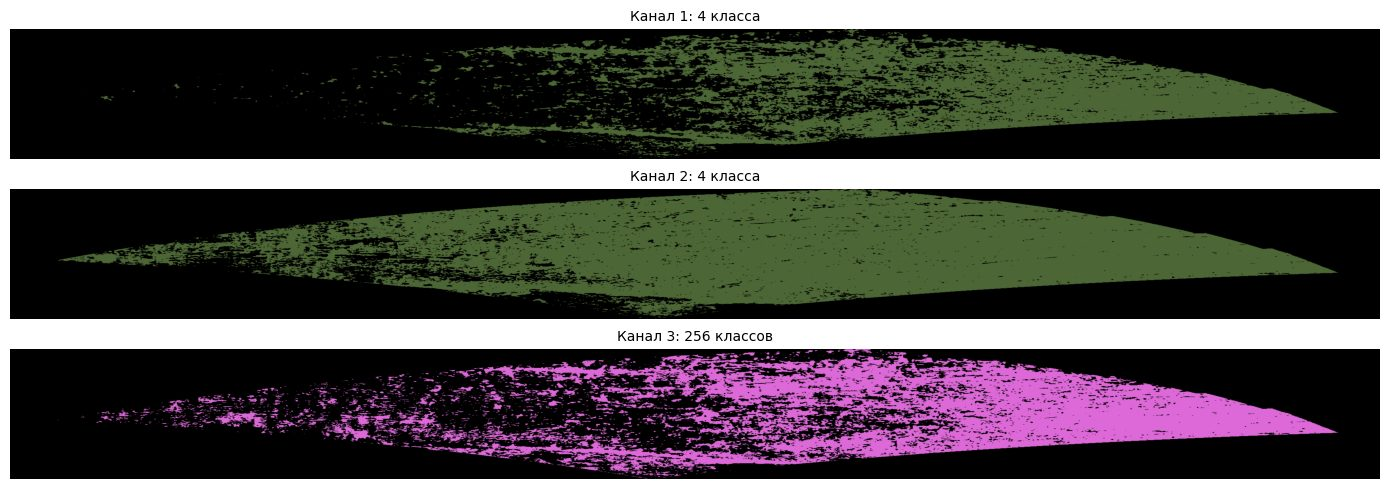

In [22]:
def segment_channel(channel, n):
    if not 1 <= n <= 256:
        raise ValueError('Количество классов должно быть от 1 до 256')
    palette = np.random.default_rng(17).integers(30, 256, (n, 3), dtype=np.uint8)
    palette[0] = 0
    classes = channel.astype(np.uint16) * n // 256
    return palette[classes]


mask_1 = segment_channel(composite[:, :, 0], 4)
mask_2 = segment_channel(composite[:, :, 1], 4)
mask_3 = segment_channel(composite[:, :, 2], 256)
fig, axes = plt.subplots(3, 1, figsize=(14, 5))
for ax, mask, title in zip(axes, [mask_1, mask_2, mask_3],
                           ['Канал 1: 4 класса', 'Канал 2: 4 класса', 'Канал 3: 256 классов']):
    ax.imshow(cv2.cvtColor(mask, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=10)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

### 4.7. Разбиение на патчи и сохранение массивов

In [23]:
def split_patches(image, size=256):
    h, w = image.shape[:2]
    h, w = h // size * size, w // size * size
    if h == 0 or w == 0:
        raise ValueError('Размер изображения меньше размера патча')
    return np.array([image[y:y + size, x:x + size]
                     for y in range(0, h, size)
                     for x in range(0, w, size)])


img_patches = split_patches(composite)
mask_patches = split_patches(mask_2)
np.save(files / 'img.npy', img_patches)
np.save(files / 'mask.npy', mask_patches)

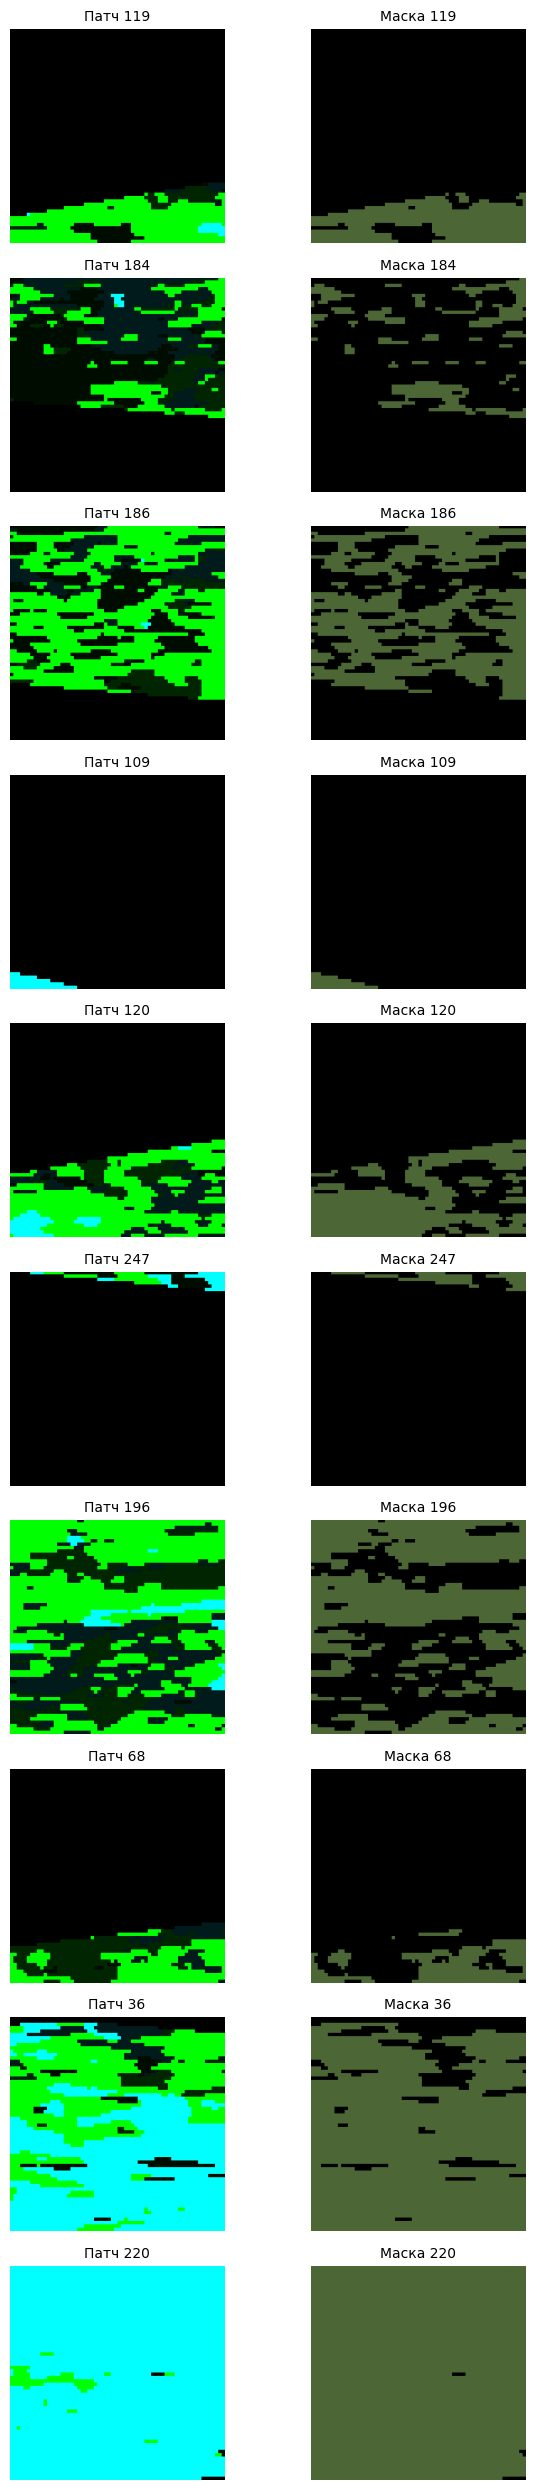

In [24]:
valid_indices = [i for i, patch in enumerate(img_patches) if np.any(patch)]
indices = np.random.default_rng(14).choice(valid_indices, 10, replace=False)
fig, axes = plt.subplots(10, 2, figsize=(7, 25))
for row, index in enumerate(indices):
    axes[row, 0].imshow(cv2.cvtColor(img_patches[index], cv2.COLOR_BGR2RGB))
    axes[row, 1].imshow(cv2.cvtColor(mask_patches[index], cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f'Патч {index}', fontsize=10)
    axes[row, 1].set_title(f'Маска {index}', fontsize=10)
    for ax in axes[row]:
        ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)